
## Data Anaysis
-it is the process of collecting , cleaning , transforming and interpreting raw data to discover the useful insights and support decision making 

collecting , examining, cleaning, tranforming, organizing, & interpreting data to extract useful info


## 1.Pandas(panel-data)
it is a open source library used for data manipulation and data analysis

dat str :
- series(1D)
-  Dataframes(2D)
  
```python
import pandas as pd 
```

## Series
it is a One dimension array data structure that can hold any type of data, where each item has a specific index name

In [1]:
import pandas as pd
marks = [87,89,90,78]
series = pd.Series(marks)# as list
print(series)
line = '=========================================='
print(line)


index = pd.Series(marks, index =['a', 'b', 'c','d'])
print(index)
print(line)

# we use the loc for the locate the data 
print(series.loc[1])
print(index.loc['b'])
series.loc[1] = 200
print(series.loc[1])## it change the located value in the series not the marks data
print(index.loc['b'])
print(line)

print(index.iloc[1])# now in the index at position b the 89 present but we can also acces it though the index
print(line)

#we can apply condition in the series
print(series[series>=90])

0    87
1    89
2    90
3    78
dtype: int64
a    87
b    89
c    90
d    78
dtype: int64
89
89
200
89
89
1    200
2     90
dtype: int64


In [2]:
#series using dictionary
students = pd.Series({
    'rahul' : 21,
    'neha' : 24,
    "abhi" : 22,
    'rajunh' : 28,
    'anu' : 29,
    'shreya' : 35
})

print(students)
print(line)

students.loc["anu"]-=5
print(students.loc["anu"])
print(students[students<25])
print(line)

print(students)


rahul     21
neha      24
abhi      22
rajunh    28
anu       29
shreya    35
dtype: int64
24
rahul    21
neha     24
abhi     22
anu      24
dtype: int64
rahul     21
neha      24
abhi      22
rajunh    28
anu       24
shreya    35
dtype: int64


## Data Frames
A two-dimensional labeled , a tabular data structure with rows and columns.

In [3]:
data = {
    'name' : ["riya", "rahul", "arjunh"],
    'age' : [21,23,21],
    'marks' : [98,87,76]
}
df = pd.DataFrame(data)
print(df)
print(line)

#lets change the indec
df = pd.DataFrame(data, index=['a', 'b', 'c'])
print(df)
print(line)

# df.loc['row_label', 'column_label']
#df.loc[:, 'column_label']          # Single column
#df.loc[:, ['Col_A', 'Col_B']]      # Multiple columns

#lets access using loc 
print(df.loc['a']) # accesing the row
print(line)
print(df.loc[:,'marks']) # accesing the column}
print(line)

# add a column
df['hobby'] = ['swimming', 'reading', 'archery']
print(df)
print(line)

# add a new row
new_row = pd.DataFrame([
    {'name':'manu', 'age':19,'hobby':'vedic_scriptures'},
    {'name':'trupti', 'age':21,'marks':89,'hobby':'traveling'}],index =['d','e'])
df = pd.concat([df, new_row])
print(df)


     name  age  marks
0    riya   21     98
1   rahul   23     87
2  arjunh   21     76
     name  age  marks
a    riya   21     98
b   rahul   23     87
c  arjunh   21     76
name     riya
age        21
marks      98
Name: a, dtype: object
a    98
b    87
c    76
Name: marks, dtype: int64
     name  age  marks     hobby
a    riya   21     98  swimming
b   rahul   23     87   reading
c  arjunh   21     76   archery
     name  age  marks             hobby
a    riya   21   98.0          swimming
b   rahul   23   87.0           reading
c  arjunh   21   76.0           archery
d    manu   19    NaN  vedic_scriptures
e  trupti   21   89.0         traveling


In [4]:
# null value
df.isnull()# - missing value
df.dropna()# - rows containg misssing values-- manu will get disappear

,name,age,marks,hobby
a,riya,21,98.0,swimming
b,rahul,23,87.0,reading
c,arjunh,21,76.0,archery
e,trupti,21,89.0,traveling


In [5]:
orders = {
    "Order_ID": [
        "ORD101",
        "ORD102",
        "ORD103",
        "ORD104",
        "ORD105",
        "ORD106",
        "ORD107",
        "ORD108",
    ],
    "Product": [
        "Laptop",
        "Headphones",
        "Mouse",
        "Laptop",
        "Keyboard",
        "Headphones",
        "Monitor",
        "Mouse",
    ],
    "Category": [
        "Electronics",
        "Accessories",
        "Accessories",
        "Electronics",
        "Accessories",
        "Accessories",
        "Electronics",
        "Accessories",
    ],
    "City": [
        "Pune",
        "Mumbai",
        "Pune",
        "Delhi",
        "Mumbai",
        "Pune",
        "Delhi",
        "Mumbai",
    ],
    "Quantity": [1, 2, 3, 1, 2, 1, 2, 4],
    "Price": [55000, 2000, 800, 55000, 1500, 2000, 12000, 800],
}

df = pd.DataFrame(orders)
print(df)
print(line)
selected = df[['Product','Category']]
print(selected)
print(line)

##show where quantity are greater than 2
print(df[df["Quantity"]>2])
print(line)

## oder from pune quantities are greater than 1
print(df[(df['Quantity']>1) & (df['City']=='Pune')])
print(line)

##calculate the revenue
df['revenue'] = df['Quantity']*df['Price']
print(df)
print(line)

##hight value
df['order_type'] = df['revenue'].apply(lambda x : 'High Value' if x>20000 else 'Normal')
print(df)
print(line)

##print only high value columns
print(df.loc[df['order_type']=='High Value'])
print(line)

# group by the city
group = df.groupby('City')['revenue'].sum()
print(group)
print('line')
print(df.groupby('City')['revenue'].mean())

  Order_ID     Product     Category    City  Quantity  Price
0   ORD101      Laptop  Electronics    Pune         1  55000
1   ORD102  Headphones  Accessories  Mumbai         2   2000
2   ORD103       Mouse  Accessories    Pune         3    800
3   ORD104      Laptop  Electronics   Delhi         1  55000
4   ORD105    Keyboard  Accessories  Mumbai         2   1500
5   ORD106  Headphones  Accessories    Pune         1   2000
6   ORD107     Monitor  Electronics   Delhi         2  12000
7   ORD108       Mouse  Accessories  Mumbai         4    800
      Product     Category
0      Laptop  Electronics
1  Headphones  Accessories
2       Mouse  Accessories
3      Laptop  Electronics
4    Keyboard  Accessories
5  Headphones  Accessories
6     Monitor  Electronics
7       Mouse  Accessories
  Order_ID Product     Category    City  Quantity  Price
2   ORD103   Mouse  Accessories    Pune         3    800
7   ORD108   Mouse  Accessories  Mumbai         4    800
  Order_ID Product     Category  City

In [6]:
import pandas as pd

placement = {
    "Student": [
        "Aarav", "Isha", "Rohan", "Meera",
        "Kabir", "Ananya", "Vivek", "Sneha"
    ],
    "Department": [
        "Computer", "IT", "Computer", "Mechanical",
        "IT", "Computer", "Mechanical", "IT"
    ],
    "Company": [
        "TCS", "Infosys", "Wipro", "TCS",
        "Infosys", "Accenture", "Wipro", "TCS"
    ],
    "Package": [
        4.5, 3.8, 7.2, 6.0, 4.5, 5.2, 4.0, 3.8
    ],
    "Placement Status": [
        "Placed", "Placed", "Placed", "Placed",
        "Placed", "Placed", "Not Placed", "Placed"
    ]
}

df = pd.DataFrame(placement)
print(df)
print(line)

###avg package by department
print(df.groupby('Department')['Package'].mean())
print(line)

##count of student place in perticular company
print(df[df['Placement Status']=='Placed'].groupby('Company')["Student"].count())
print(line)

  Student  Department    Company  Package Placement Status
0   Aarav    Computer        TCS      4.5           Placed
1    Isha          IT    Infosys      3.8           Placed
2   Rohan    Computer      Wipro      7.2           Placed
3   Meera  Mechanical        TCS      6.0           Placed
4   Kabir          IT    Infosys      4.5           Placed
5  Ananya    Computer  Accenture      5.2           Placed
6   Vivek  Mechanical      Wipro      4.0       Not Placed
7   Sneha          IT        TCS      3.8           Placed
Department
Computer      5.633333
IT            4.033333
Mechanical    5.000000
Name: Package, dtype: float64
Company
Accenture    1
Infosys      2
TCS          3
Wipro        1
Name: Student, dtype: int64


In [7]:
import pandas as pd

df = pd.DataFrame({
    "date": [
        "2026-08-01",
        "2026-08-02",
        "2026-08-03",
        "2026-08-04",
        "2026-08-05"
    ],
    "traffic": [120, 150, 180, 210, 190]
})

# Convert string to datetime
df["date"] = pd.to_datetime(df["date"])

# Extractingg date components
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["day_of_week"] = df["date"].dt.dayofweek
df["day_name"] = df["date"].dt.day_name()

print(df)

        date  traffic  year  month  day  day_of_week   day_name
0 2026-08-01      120  2026      8    1            5   Saturday
1 2026-08-02      150  2026      8    2            6     Sunday
2 2026-08-03      180  2026      8    3            0     Monday
3 2026-08-04      210  2026      8    4            1    Tuesday
4 2026-08-05      190  2026      8    5            2  Wednesday


In [8]:
print(
    df[
        (df['date']>"2026-08-01") 
        &
        (df['date']<"2026-08-04")
        
        ]
)

df[df["date"].between("2026-08-02", "2026-08-04")]

        date  traffic  year  month  day  day_of_week day_name
1 2026-08-02      150  2026      8    2            6   Sunday
2 2026-08-03      180  2026      8    3            0   Monday


,date,traffic,year,month,day,day_of_week,day_name
1,2026-08-02,150,2026,8,2,6,Sunday
2,2026-08-03,180,2026,8,3,0,Monday
3,2026-08-04,210,2026,8,4,1,Tuesday


## Advanced DataFrame Operations

Now I am continuing from the basic DataFrame work above. The next part is about answering actual business questions from a dataset.


In [9]:
# Recreate the order DataFrame used for the practical work
orders = pd.DataFrame({
    "Order_ID": ["ORD101", "ORD102", "ORD103", "ORD104", "ORD105", "ORD106", "ORD107", "ORD108"],
    "Product": ["Laptop", "Headphones", "Mouse", "Laptop", "Keyboard", "Headphones", "Monitor", "Mouse"],
    "Category": ["Electronics", "Accessories", "Accessories", "Electronics",
                  "Accessories", "Accessories", "Electronics", "Accessories"],
    "City": ["Pune", "Mumbai", "Pune", "Delhi", "Mumbai", "Pune", "Delhi", "Mumbai"],
    "Quantity": [1, 2, 3, 1, 2, 1, 2, 4],
    "Price": [55000, 2000, 800, 55000, 2500, 2000, 12000, 800]
})

orders


,Order_ID,Product,Category,City,Quantity,Price
0,ORD101,Laptop,Electronics,Pune,1,55000
1,ORD102,Headphones,Accessories,Mumbai,2,2000
2,ORD103,Mouse,Accessories,Pune,3,800
3,ORD104,Laptop,Electronics,Delhi,1,55000
4,ORD105,Keyboard,Accessories,Mumbai,2,2500
5,ORD106,Headphones,Accessories,Pune,1,2000
6,ORD107,Monitor,Electronics,Delhi,2,12000
7,ORD108,Mouse,Accessories,Mumbai,4,800


### Selecting only required columns

In a real project, we may have many columns, but the business question may need only a few.


In [10]:
selected = orders[["Product", "City", "Quantity", "Price"]]
print(selected)


      Product    City  Quantity  Price
0      Laptop    Pune         1  55000
1  Headphones  Mumbai         2   2000
2       Mouse    Pune         3    800
3      Laptop   Delhi         1  55000
4    Keyboard  Mumbai         2   2500
5  Headphones    Pune         1   2000
6     Monitor   Delhi         2  12000
7       Mouse  Mumbai         4    800


### Filtering with one condition


In [11]:
high_quantity = orders[orders["Quantity"] > 2]
print(high_quantity)


  Order_ID Product     Category    City  Quantity  Price
2   ORD103   Mouse  Accessories    Pune         3    800
7   ORD108   Mouse  Accessories  Mumbai         4    800


### Filtering with multiple conditions

Business question: show orders from Pune where quantity is greater than 1.


In [12]:
pune_orders = orders[(orders["City"] == "Pune") & (orders["Quantity"] > 1)]
print(pune_orders)


  Order_ID Product     Category  City  Quantity  Price
2   ORD103   Mouse  Accessories  Pune         3    800


### Sorting

`ascending=False` gives largest to smallest.


In [13]:
sorted_orders = orders.sort_values("Price", ascending=False)
print(sorted_orders)


  Order_ID     Product     Category    City  Quantity  Price
0   ORD101      Laptop  Electronics    Pune         1  55000
3   ORD104      Laptop  Electronics   Delhi         1  55000
6   ORD107     Monitor  Electronics   Delhi         2  12000
4   ORD105    Keyboard  Accessories  Mumbai         2   2500
5   ORD106  Headphones  Accessories    Pune         1   2000
1   ORD102  Headphones  Accessories  Mumbai         2   2000
2   ORD103       Mouse  Accessories    Pune         3    800
7   ORD108       Mouse  Accessories  Mumbai         4    800


### Top and bottom values


In [14]:
print("Top 3 orders by price:")
print(orders.nlargest(3, "Price"))

print("\nBottom 3 orders by price:")
print(orders.nsmallest(3, "Price"))


Top 3 orders by price:
  Order_ID  Product     Category   City  Quantity  Price
0   ORD101   Laptop  Electronics   Pune         1  55000
3   ORD104   Laptop  Electronics  Delhi         1  55000
6   ORD107  Monitor  Electronics  Delhi         2  12000

Bottom 3 orders by price:
  Order_ID     Product     Category    City  Quantity  Price
2   ORD103       Mouse  Accessories    Pune         3    800
7   ORD108       Mouse  Accessories  Mumbai         4    800
1   ORD102  Headphones  Accessories  Mumbai         2   2000


## Grouping and Aggregation

Grouping is useful when the question is about categories, for example revenue by city or average price by category.


In [15]:
orders["Revenue"] = orders["Quantity"] * orders["Price"]

print("Revenue by city:")
print(orders.groupby("City")["Revenue"].sum())

print("\nAverage revenue by category:")
print(orders.groupby("Category")["Revenue"].mean())


Revenue by city:
City
Delhi     79000
Mumbai    12200
Pune      59400
Name: Revenue, dtype: int64

Average revenue by category:
Category
Accessories     3320.000000
Electronics    44666.666667
Name: Revenue, dtype: float64


## Time Series and Datetime

Dates should be converted to datetime before date-based analysis.


In [16]:
dates_df = pd.DataFrame({
    "date": ["2026-08-01", "2026-08-02", "2026-08-03",
             "2026-08-04", "2026-08-05", "2026-08-06"],
    "sales": [25000, 28000, 35000, 42000, 50000, 58000]
})

dates_df["date"] = pd.to_datetime(dates_df["date"])
dates_df["year"] = dates_df["date"].dt.year
dates_df["month"] = dates_df["date"].dt.month
dates_df["day"] = dates_df["date"].dt.day
dates_df["day_name"] = dates_df["date"].dt.day_name()

print(dates_df)


        date  sales  year  month  day   day_name
0 2026-08-01  25000  2026      8    1   Saturday
1 2026-08-02  28000  2026      8    2     Sunday
2 2026-08-03  35000  2026      8    3     Monday
3 2026-08-04  42000  2026      8    4    Tuesday
4 2026-08-05  50000  2026      8    5  Wednesday
5 2026-08-06  58000  2026      8    6   Thursday


### Filtering dates


In [17]:
print(dates_df[dates_df["date"].between("2026-08-02", "2026-08-04")])


        date  sales  year  month  day day_name
1 2026-08-02  28000  2026      8    2   Sunday
2 2026-08-03  35000  2026      8    3   Monday
3 2026-08-04  42000  2026      8    4  Tuesday


## Assignment 1 - Merge Practical

**Task given in class:** create employee information in one DataFrame and salary information in another DataFrame. Use Employee ID as the common column. Perform inner, left, right and outer merges, and explain why the outputs are different.


In [18]:
import pandas as pd

employees = pd.DataFrame({
    "Employee_ID": [101, 102, 103, 104],
    "Name": ["Amit", "Neha", "Rahul", "Pooja"],
    "Department": ["IT", "HR", "Finance", "Sales"]
})

salary = pd.DataFrame({
    "Employee_ID": [101, 102, 104, 105],
    "Salary": [45000, 40000, 50000, 55000]
})

inner_merge = pd.merge(employees, salary, on="Employee_ID", how="inner")
left_merge = pd.merge(employees, salary, on="Employee_ID", how="left")
right_merge = pd.merge(employees, salary, on="Employee_ID", how="right")
outer_merge = pd.merge(employees, salary, on="Employee_ID", how="outer")

print("EMPLOYEE DATA")
print(employees)

print("\nSALARY DATA")
print(salary)

print("\nINNER MERGE")
print(inner_merge)

print("\nLEFT MERGE")
print(left_merge)

print("\nRIGHT MERGE")
print(right_merge)

print("\nOUTER MERGE")
print(outer_merge)


EMPLOYEE DATA
   Employee_ID   Name Department
0          101   Amit         IT
1          102   Neha         HR
2          103  Rahul    Finance
3          104  Pooja      Sales

SALARY DATA
   Employee_ID  Salary
0          101   45000
1          102   40000
2          104   50000
3          105   55000

INNER MERGE
   Employee_ID   Name Department  Salary
0          101   Amit         IT   45000
1          102   Neha         HR   40000
2          104  Pooja      Sales   50000

LEFT MERGE
   Employee_ID   Name Department   Salary
0          101   Amit         IT  45000.0
1          102   Neha         HR  40000.0
2          103  Rahul    Finance      NaN
3          104  Pooja      Sales  50000.0

RIGHT MERGE
   Employee_ID   Name Department  Salary
0          101   Amit         IT   45000
1          102   Neha         HR   40000
2          104  Pooja      Sales   50000
3          105    NaN        NaN   55000

OUTER MERGE
   Employee_ID   Name Department   Salary
0          101   Amit

### Merge explanation

- **Inner merge:** keeps only Employee IDs present in both DataFrames.
- **Left merge:** keeps every employee from the left DataFrame.
- **Right merge:** keeps every record from the right DataFrame.
- **Outer merge:** keeps records from both DataFrames.

The common column here is `Employee_ID`.


## Data Input and Output

Real data can come from CSV, Excel, JSON, databases and APIs. The following example makes a small CSV inside the notebook so the code can run without needing an external file.


In [19]:
# Create a CSV file inside the notebook for practice
csv_data = pd.DataFrame({
    "Employee_ID": [101, 102, 103, 104, 105],
    "Name": ["Amit", "Neha", "Rahul", "Pooja", "Rohan"],
    "Department": ["IT", "HR", "Finance", "Sales", "IT"],
    "Salary": [45000, 40000, 65000, 50000, 72000],
    "Experience": [2, 1, 4, 3, 5]
})

csv_data.to_csv("employees.csv", index=False)

df_csv = pd.read_csv("employees.csv")

print(df_csv)
print("\nShape:", df_csv.shape)
print("\nColumns:", list(df_csv.columns))
print("\nData types:")
print(df_csv.dtypes)


   Employee_ID   Name Department  Salary  Experience
0          101   Amit         IT   45000           2
1          102   Neha         HR   40000           1
2          103  Rahul    Finance   65000           4
3          104  Pooja      Sales   50000           3
4          105  Rohan         IT   72000           5

Shape: (5, 5)

Columns: ['Employee_ID', 'Name', 'Department', 'Salary', 'Experience']

Data types:
Employee_ID     int64
Name           object
Department     object
Salary          int64
Experience      int64
dtype: object


In [20]:
# Filter employees with salary above 50,000
high_salary = df_csv[df_csv["Salary"] > 50000]
print(high_salary)

# Average salary
average_salary = df_csv["Salary"].mean()
print("\nAverage salary:", average_salary)

# Create annual salary
df_csv["Annual_Salary"] = df_csv["Salary"] * 12
print("\nUpdated DataFrame:")
print(df_csv)

# Export the updated DataFrame
df_csv.to_csv("employees_updated.csv", index=False)
print("\nUpdated CSV file created successfully.")


   Employee_ID   Name Department  Salary  Experience
2          103  Rahul    Finance   65000           4
4          105  Rohan         IT   72000           5

Average salary: 54400.0

Updated DataFrame:
   Employee_ID   Name Department  Salary  Experience  Annual_Salary
0          101   Amit         IT   45000           2         540000
1          102   Neha         HR   40000           1         480000
2          103  Rahul    Finance   65000           4         780000
3          104  Pooja      Sales   50000           3         600000
4          105  Rohan         IT   72000           5         864000

Updated CSV file created successfully.


## Reading and Writing Excel


In [21]:
df_csv.to_excel("employees_updated.xlsx", index=False)

df_excel = pd.read_excel("employees_updated.xlsx")
print(df_excel)


   Employee_ID   Name Department  Salary  Experience  Annual_Salary
0          101   Amit         IT   45000           2         540000
1          102   Neha         HR   40000           1         480000
2          103  Rahul    Finance   65000           4         780000
3          104  Pooja      Sales   50000           3         600000
4          105  Rohan         IT   72000           5         864000


## JSON Input Example


In [22]:
json_data = [
    {"Employee_ID": 101, "Name": "Amit", "Department": "IT", "Salary": 45000},
    {"Employee_ID": 102, "Name": "Neha", "Department": "HR", "Salary": 40000}
]

with open("employees.json", "w", encoding="utf-8") as f:
    import json
    json.dump(json_data, f, indent=4)

df_json = pd.read_json("employees.json")
print(df_json)


   Employee_ID  Name Department  Salary
0          101  Amit         IT   45000
1          102  Neha         HR   40000


## Handling Duplicate Data

Duplicate rows can lead to wrong analysis. A repeated customer or employee ID is not automatically a duplicate record because the same ID can appear in genuine transactions. The whole row or the selected columns should be considered.


In [23]:
duplicate_data = pd.DataFrame({
    "Employee_ID": [1, 2, 1, 3],
    "Name": ["Rahul", "Priya", "Rahul", "Amit"],
    "Department": ["IT", "HR", "IT", "Sales"]
})

print("Original data:")
print(duplicate_data)

print("\nDuplicate check:")
print(duplicate_data.duplicated())

clean_data = duplicate_data.drop_duplicates()
print("\nAfter removing duplicate rows:")
print(clean_data)


Original data:
   Employee_ID   Name Department
0            1  Rahul         IT
1            2  Priya         HR
2            1  Rahul         IT
3            3   Amit      Sales

Duplicate check:
0    False
1    False
2     True
3    False
dtype: bool

After removing duplicate rows:
   Employee_ID   Name Department
0            1  Rahul         IT
1            2  Priya         HR
3            3   Amit      Sales


## Arithmetic Operations in Pandas


In [24]:
sales = pd.DataFrame({
    "Product": ["Laptop", "Phone", "Headphones", "Keyboard"],
    "Quantity": [2, 5, 3, 4],
    "Price": [55000, 30000, 2000, 1500]
})

sales["Revenue"] = sales["Quantity"] * sales["Price"]
sales["Discount"] = sales["Revenue"] * 0.20
sales["Amount_After_Discount"] = sales["Revenue"] - sales["Discount"]
sales["GST"] = sales["Amount_After_Discount"] * 0.18
sales["Final_Bill_Amount"] = sales["Amount_After_Discount"] + sales["GST"]

print(sales)


      Product  Quantity  ...      GST  Final_Bill_Amount
0      Laptop         2  ...  15840.0           103840.0
1       Phone         5  ...  21600.0           141600.0
2  Headphones         3  ...    864.0             5664.0
3    Keyboard         4  ...    864.0             5664.0

[4 rows x 8 columns]


## Assignment 2 - E-Commerce Arithmetic

This is the business calculation task from the lecture.

**Required columns/calculations:**
1. Product
2. Quantity
3. Price
4. Revenue
5. 20% Discount
6. Amount after discount
7. 18% GST
8. Final bill amount


In [25]:
# Assignment 2 completed
ecommerce = pd.DataFrame({
    "Product": ["Laptop", "Phone", "Headphones", "Keyboard"],
    "Quantity": [2, 5, 3, 4],
    "Price": [55000, 30000, 2000, 1500]
})

ecommerce["Revenue"] = ecommerce["Quantity"] * ecommerce["Price"]
ecommerce["Discount"] = ecommerce["Revenue"] * 0.20
ecommerce["Amount_After_Discount"] = ecommerce["Revenue"] - ecommerce["Discount"]
ecommerce["GST"] = ecommerce["Amount_After_Discount"] * 0.18
ecommerce["Final_Bill_Amount"] = ecommerce["Amount_After_Discount"] + ecommerce["GST"]

print(ecommerce)


      Product  Quantity  ...      GST  Final_Bill_Amount
0      Laptop         2  ...  15840.0           103840.0
1       Phone         5  ...  21600.0           141600.0
2  Headphones         3  ...    864.0             5664.0
3    Keyboard         4  ...    864.0             5664.0

[4 rows x 8 columns]


### Vectorized arithmetic

The same operation is applied to the whole column. No Python loop is required.


In [26]:
# Example: add 5,000 to every salary
salary_demo = pd.DataFrame({
    "Employee": ["Amit", "Neha", "Rahul", "Pooja"],
    "Salary": [30000, 40000, 50000, 60000]
})

salary_demo["New_Salary"] = salary_demo["Salary"] + 5000
print(salary_demo)


  Employee  Salary  New_Salary
0     Amit   30000       35000
1     Neha   40000       45000
2    Rahul   50000       55000
3    Pooja   60000       65000


## Broadcasting

A single value can be applied across many elements. For example, the same bonus can be added to every employee salary.


In [27]:
bonus = 5000
salary_demo["Salary_After_Bonus"] = salary_demo["Salary"] + bonus
print(salary_demo)


  Employee  Salary  New_Salary  Salary_After_Bonus
0     Amit   30000       35000               35000
1     Neha   40000       45000               45000
2    Rahul   50000       55000               55000
3    Pooja   60000       65000               65000


## Iteration with `itertuples()`

Iteration is useful when each row needs customized processing. It should not replace a simple vectorized operation when Pandas can do the work directly.


In [28]:
for row in salary_demo.itertuples(index=False):
    print(f"{row.Employee} earns {row.Salary} and after bonus earns {row.Salary_After_Bonus}")


Amit earns 30000 and after bonus earns 35000
Neha earns 40000 and after bonus earns 45000
Rahul earns 50000 and after bonus earns 55000
Pooja earns 60000 and after bonus earns 65000


## `iterrows()` and `itertuples()`


In [29]:
print("Using iterrows():")
for index, row in salary_demo.iterrows():
    print(index, row["Employee"], row["Salary"])

print("\nUsing itertuples():")
for row in salary_demo.itertuples():
    print(row.Index, row.Employee, row.Salary)


Using iterrows():
0 Amit 30000
1 Neha 40000
2 Rahul 50000
3 Pooja 60000

Using itertuples():
0 Amit 30000
1 Neha 40000
2 Rahul 50000
3 Pooja 60000


## Assignment 3 - NumPy Practice


In [30]:
import numpy as np

arr = np.array([10, 20, 30, 40, 50])

print("Array:", arr)
print("Mean:", np.mean(arr))
print("Maximum:", np.max(arr))
print("Sum:", np.sum(arr))
print("Double:", arr * 2)
print("Greater than 25:", arr[arr > 25])


Array: [10 20 30 40 50]
Mean: 30.0
Maximum: 50
Sum: 150
Double: [ 20  40  60  80 100]
Greater than 25: [30 40 50]


### NumPy shape, dimensions and size


In [31]:
arr_2d = np.array([
    [1, 2, 3],
    [4, 5, 6]
])

print("Array:")
print(arr_2d)
print("\nDimensions:", arr_2d.ndim)
print("Shape:", arr_2d.shape)
print("Size:", arr_2d.size)


Array:
[[1 2 3]
 [4 5 6]]

Dimensions: 2
Shape: (2, 3)
Size: 6


### NumPy array creation functions


In [32]:
print("Zeros:")
print(np.zeros(5))

print("\nOnes:")
print(np.ones(5))

print("\nArange:")
print(np.arange(1, 6))


Zeros:
[0. 0. 0. 0. 0.]

Ones:
[1. 1. 1. 1. 1.]

Arange:
[1 2 3 4 5]


### NumPy `reshape()`


In [33]:
arr = np.array([1, 2, 3, 4, 5, 6])
reshaped = arr.reshape(2, 3)

print("Original:")
print(arr)

print("\nReshaped:")
print(reshaped)


Original:
[1 2 3 4 5 6]

Reshaped:
[[1 2 3]
 [4 5 6]]


## Data Visualization

After analyzing data, visualization is used to communicate patterns and findings clearly.

The important rule from class is: **first ask the business question, then choose the chart.**


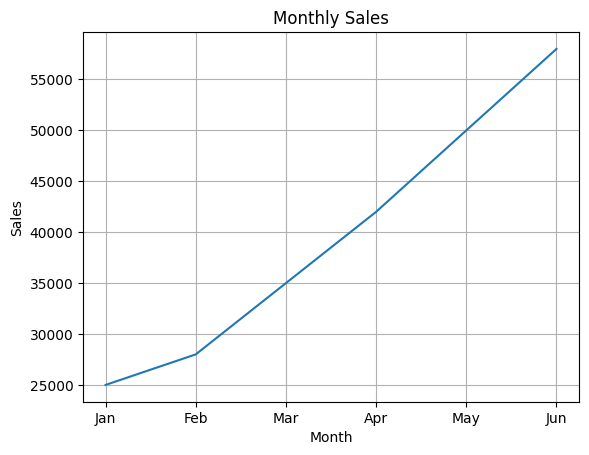

In [34]:
import matplotlib.pyplot as plt

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
sales_values = [25000, 28000, 35000, 42000, 50000, 58000]

plt.plot(months, sales_values)
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.grid()
plt.show()


### Bar chart

Used for comparing categories.


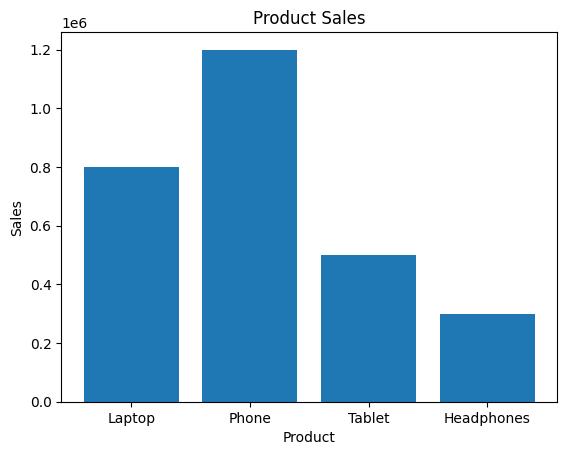

In [35]:
products = ["Laptop", "Phone", "Tablet", "Headphones"]
product_sales = [800000, 1200000, 500000, 300000]

plt.bar(products, product_sales)
plt.title("Product Sales")
plt.xlabel("Product")
plt.ylabel("Sales")
plt.show()


### Pie chart

Used to show parts of a whole.


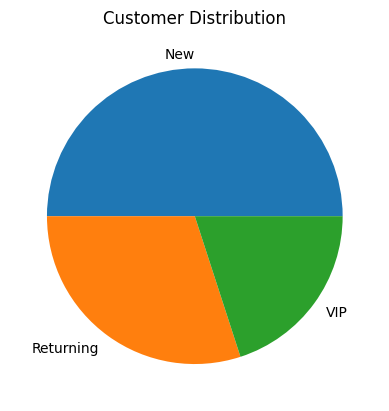

In [36]:
categories = ["New", "Returning", "VIP"]
customers = [50, 30, 20]

plt.pie(customers, labels=categories)
plt.title("Customer Distribution")
plt.show()


### Scatter plot

Used to inspect the relationship between two numerical variables.


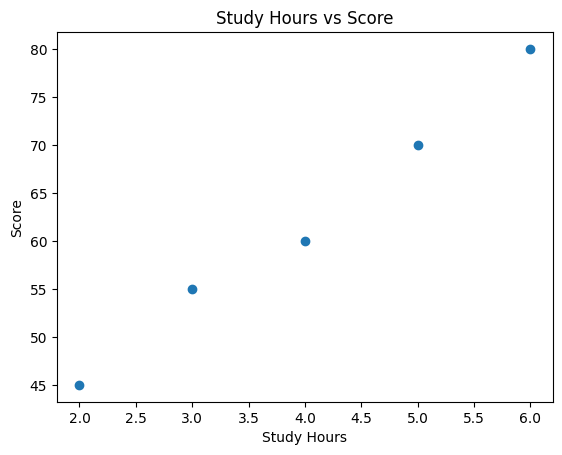

In [37]:
study_hours = [2, 3, 4, 5, 6]
scores = [45, 55, 60, 70, 80]

plt.scatter(study_hours, scores)
plt.title("Study Hours vs Score")
plt.xlabel("Study Hours")
plt.ylabel("Score")
plt.show()


### Histogram

Used to understand the distribution of numerical data.


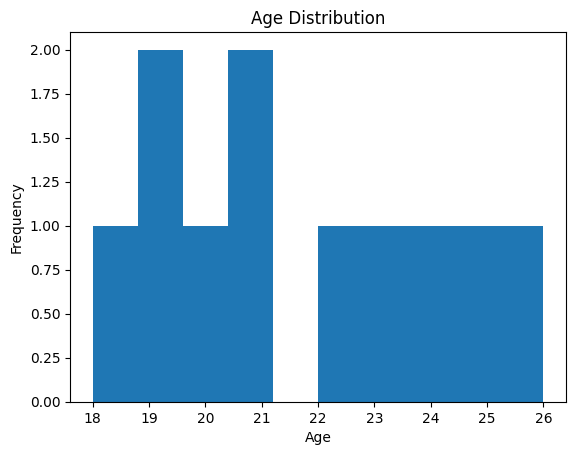

In [38]:
ages = [18, 19, 19, 20, 21, 21, 22, 23, 24, 25, 26]

plt.hist(ages)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()


### Box plot

Used to understand numerical distribution and identify possible outliers.


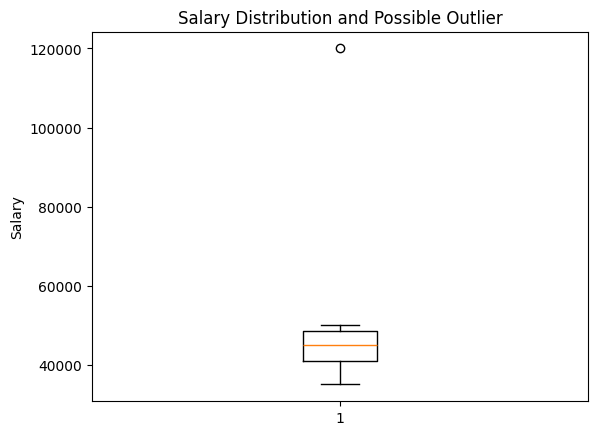

In [39]:
salary_values = [35000, 40000, 42000, 45000, 47000, 50000, 120000]

plt.boxplot(salary_values)
plt.title("Salary Distribution and Possible Outlier")
plt.ylabel("Salary")
plt.show()


## Seaborn

Seaborn is built on top of Matplotlib and is especially convenient for statistical visualization and DataFrames.


In [40]:
import seaborn as sns

sns.set_theme()

visual_df = pd.DataFrame({
    "Department": ["IT", "IT", "HR", "HR", "Sales", "Sales", "IT", "Sales"],
    "Experience": [2, 5, 1, 3, 2, 4, 6, 5],
    "Salary": [40000, 70000, 35000, 45000, 42000, 60000, 80000, 65000]
})

print(visual_df)


  Department  Experience  Salary
0         IT           2   40000
1         IT           5   70000
2         HR           1   35000
3         HR           3   45000
4      Sales           2   42000
5      Sales           4   60000
6         IT           6   80000
7      Sales           5   65000


### Count plot

Question: How many employees are in each department?


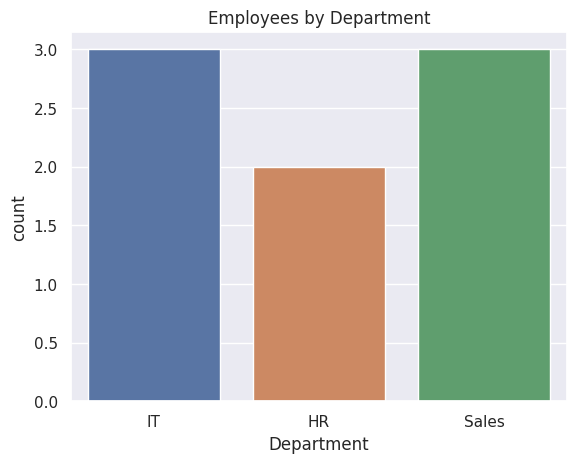

In [41]:
sns.countplot(data=visual_df, x="Department", hue="Department", legend=False)
plt.title("Employees by Department")
plt.show()


### Bar plot

Question: What is the salary statistic by department?


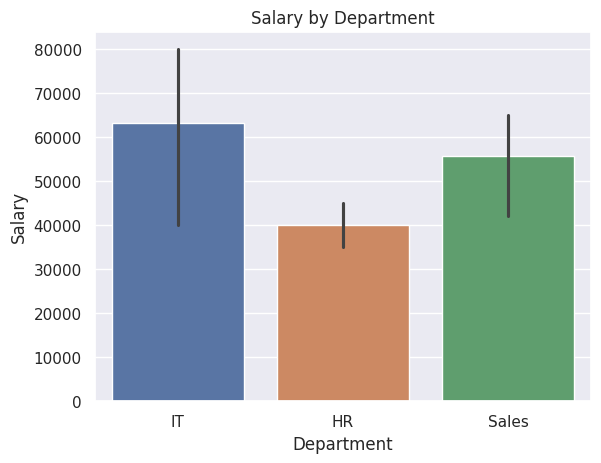

In [42]:
sns.barplot(data=visual_df, x="Department", y="Salary", hue="Department", legend=False)
plt.title("Salary by Department")
plt.show()


### Box plot using Seaborn


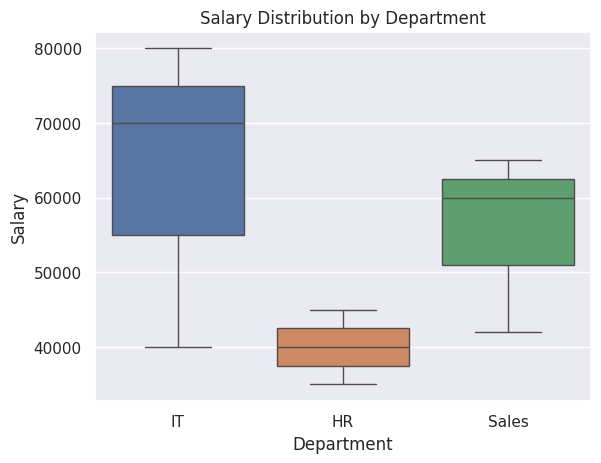

In [43]:
sns.boxplot(data=visual_df, x="Department", y="Salary", hue="Department", legend=False)
plt.title("Salary Distribution by Department")
plt.show()


### Scatter plot with `hue`

`hue` can be used to visually distinguish groups.


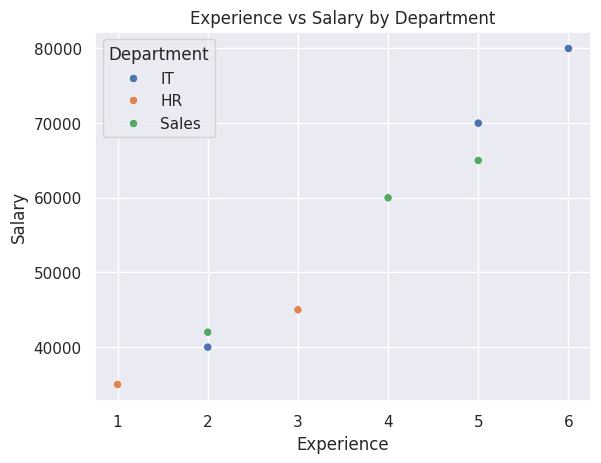

In [44]:
sns.scatterplot(
    data=visual_df,
    x="Experience",
    y="Salary",
    hue="Department"
)
plt.title("Experience vs Salary by Department")
plt.show()


### Line plot with multiple groups


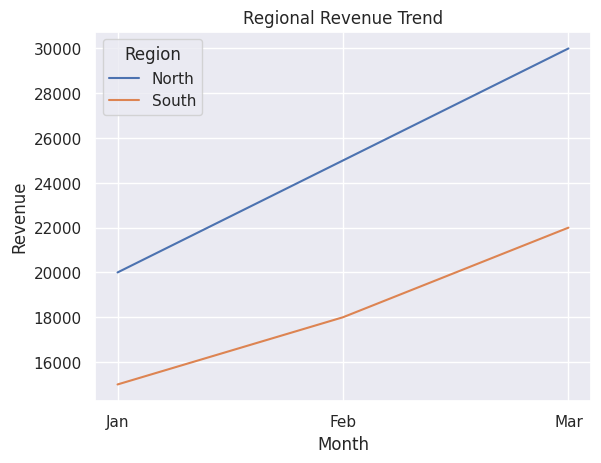

In [45]:
monthly = pd.DataFrame({
    "Month": ["Jan", "Feb", "Mar", "Jan", "Feb", "Mar"],
    "Revenue": [20000, 25000, 30000, 15000, 18000, 22000],
    "Region": ["North", "North", "North", "South", "South", "South"]
})

sns.lineplot(data=monthly, x="Month", y="Revenue", hue="Region")
plt.title("Regional Revenue Trend")
plt.show()


## Complete Mini Data Processing Workflow

This combines the major Pandas concepts taught in the module.


In [46]:
# Step 1: create customer and order data
customers = pd.DataFrame({
    "Customer_ID": [1, 2, 3, 4],
    "Customer_Name": ["Rahul", "Priya", "Amit", "Neha"],
    "City": ["Pune", "Mumbai", "Delhi", "Pune"]
})

orders = pd.DataFrame({
    "Order_ID": [101, 102, 103, 104, 105],
    "Customer_ID": [1, 2, 1, 4, 3],
    "Product": ["Laptop", "Phone", "Mouse", "Keyboard", "Tablet"],
    "Quantity": [1, 2, 3, 2, 1],
    "Price": [55000, 30000, 800, 2500, 18000],
    "Order_Date": ["2026-08-01", "2026-08-02", "2026-08-03",
                   "2026-08-04", "2026-08-05"]
})

# Step 2: merge
final_df = pd.merge(orders, customers, on="Customer_ID", how="left")

# Step 3: transform
final_df["Revenue"] = final_df["Quantity"] * final_df["Price"]

# Step 4: datetime
final_df["Order_Date"] = pd.to_datetime(final_df["Order_Date"])
final_df["Year"] = final_df["Order_Date"].dt.year
final_df["Month"] = final_df["Order_Date"].dt.month

# Step 5: filter
high_revenue = final_df[final_df["Revenue"] > 10000]

# Step 6: sort
high_revenue = high_revenue.sort_values("Revenue", ascending=False)

print(high_revenue)


   Order_ID  Customer_ID Product  Quantity  ...    City Revenue  Year Month
1       102            2   Phone         2  ...  Mumbai   60000  2026     8
0       101            1  Laptop         1  ...    Pune   55000  2026     8
4       105            3  Tablet         1  ...   Delhi   18000  2026     8

[3 rows x 11 columns]
